# Issue #330 — Causal lagged regime state

One Beijing issue is one sample.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parents[2]
OUT=ROOT/'results/regime_state'

In [2]:
decision=json.loads((OUT/'decision.json').read_text()); decision

{'allocator_nonzero_issues': 9,
 'allocator_observable_issues': 252,
 'allocator_positive_issues': 5,
 'bootstrap_positive_calibration_slices': 0,
 'claim_boundary': 'HISTORICAL_WALK_FORWARD_DIAGNOSTIC',
 'consistent_calibration_targets': 0,
 'disposition': 'SPARSE_RESPONSE_REDESIGN',
 'issue': 330,
 'max_abs_calibration_lag1': 0.11680207722618192,
 'next_moe_interface': 'MULTITASK_LAGGED_CALIBRATION_STATE',
 'promotion': False,
 'unlock_210': False}

In [3]:
state=pd.read_parquet(OUT/'state_ledger.parquet'); metrics=pd.read_csv(OUT/'prediction_metrics.csv'); state.groupby('issue_year').size()

issue_year
2020    38
2021    63
2022    62
2023    53
2024    66
dtype: int64

In [4]:
state.groupby('issue_year')[['eu_brier','line_brier','eu_top2_residual','line_top2_residual','allocator_delta']].mean()

,eu_brier,line_brier,eu_top2_residual,line_top2_residual,allocator_delta
issue_year,,,,,
2020,0.647670,0.657309,0.008743,0.000147,-32.162165
2021,0.646704,0.659764,0.000206,-0.004804,0.643177
2022,0.647776,0.660078,-0.002367,-0.005846,50.412934
2023,0.646986,0.658750,0.001562,-0.001542,-5.459686
2024,0.646213,0.658471,-0.000896,-0.001617,135.237087


In [5]:
metrics[(metrics.issue_year.isin([2023,2024])) & (metrics.condition.isin(['CURRENT_RIDGE','COMBINED_HGBR','COMBINED_HGBR_STATE_SHIFT']))]

,target,issue_year,condition,issues,mse,mae,spearman,direction_accuracy_nonzero,prior_mse,mse_lift_vs_prior
6,allocator_delta,2023,COMBINED_HGBR,50,5906.752592,50.645287,-0.202938,0.000000,1792.501442,-4114.251150
7,allocator_delta,2023,COMBINED_HGBR_STATE_SHIFT,50,4345.340677,47.455043,-0.014849,0.000000,1792.501442,-2552.839235
9,allocator_delta,2023,CURRENT_RIDGE,50,10662.743203,73.815056,-0.064346,0.000000,1792.501442,-8870.241761
12,allocator_delta,2024,COMBINED_HGBR,60,579798.143321,219.159749,-0.006875,0.500000,569376.965346,-10421.177975
13,allocator_delta,2024,COMBINED_HGBR_STATE_SHIFT,60,580474.529229,219.611864,-0.057250,0.500000,569376.965346,-11097.563884
15,allocator_delta,2024,CURRENT_RIDGE,60,549573.061651,219.652942,0.240503,1.000000,569376.965346,19803.903695
24,eu_brier,2023,COMBINED_HGBR,53,0.000153,0.010592,0.006692,1.000000,0.000150,-0.000003
25,eu_brier,2023,COMBINED_HGBR_STATE_SHIFT,53,0.000152,0.009962,0.140300,1.000000,0.000150,-0.000002
27,eu_brier,2023,CURRENT_RIDGE,53,0.000185,0.010007,0.032656,1.000000,0.000150,-0.000035
30,eu_brier,2024,COMBINED_HGBR,66,0.000248,0.011513,-0.000188,1.000000,0.000180,-0.000067


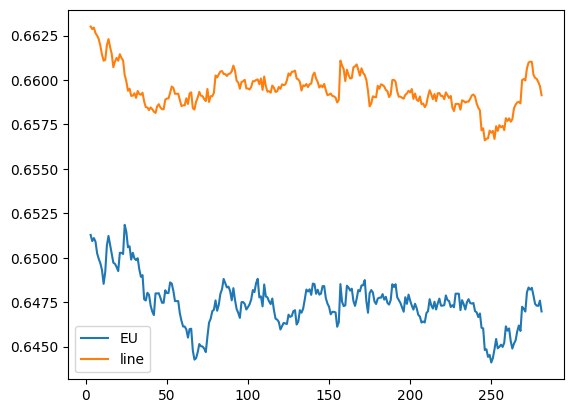

In [6]:
ordered=state.sort_values(['issue_anchor_ts','issue_code']).reset_index(drop=True); plt.plot(ordered.lag_eu_brier_ewm20,label='EU'); plt.plot(ordered.lag_line_brier_ewm20,label='line'); plt.legend(); plt.show()